# SCENIC+ links: search space, region-to-gene and TF-to-gene

SCENIC+ builds enhancer-driven gene regulatory networks (eRegulons) from paired scRNA +
scATAC data. This tutorial covers the three link tables it combines into eRegulons:

1. the **search space**: which regions may regulate which gene (gene body ± 150 kb);
2. **region-to-gene** links: how well the accessibility of each region in a gene's search
   space predicts that gene's expression (gradient boosting / random forest importance,
   signed by Spearman correlation);
3. **TF-to-gene** links: GRNBoost2 regressions of every gene on the expression of the
   transcription factors, signed by Pearson correlation.

`epione.scenic` reimplements these steps without scenicplus, arboreto, dask or ray. The
tree models are a numba port of the scikit-learn 1.3.2 code path SCENIC+ was built on, so
the importances are **bit-identical** to scenicplus 1.0 whatever scikit-learn is installed
(see the parity table at the end).

Data: the 10x multiome human cerebellum 3k dataset of the official SCENIC+ tutorial, with
the authors' cell annotation. Everything is downloaded with `pooch` and processed with
Epione.

In [1]:
import os
import tarfile
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pooch
import scanpy as sc

import epione as epi
import epione.scenic as scenic

DATA = Path(os.environ.get("EPIONE_SCENIC_TUTORIAL_DATA", "data_scenic_cerebellum"))
DATA.mkdir(parents=True, exist_ok=True)
N_JOBS = int(os.environ.get("EPIONE_N_JOBS", "8"))

TENX = "https://cf.10xgenomics.com/samples/cell-arc/2.0.0/human_brain_3k/"
FILES = {
    "human_brain_3k_filtered_feature_bc_matrix.tar.gz": (TENX + "human_brain_3k_filtered_feature_bc_matrix.tar.gz",
        "81a386c1f733e48d8fa6026e334e288333b2ad5586f9d4088bfe8b7528996fd4"),
    "human_brain_3k_atac_fragments.tsv.gz": (TENX + "human_brain_3k_atac_fragments.tsv.gz",
        "dd3513999f458e97fdf635cc0641df337c734119b122074da9dcfda17af17226"),
    "human_brain_3k_atac_fragments.tsv.gz.tbi": (TENX + "human_brain_3k_atac_fragments.tsv.gz.tbi",
        "7d89aae2ebef104d8491bedf5cccdbe3fe69d53a142071019a7ed2739b85fdd6"),
    "human_brain_3k_atac_peaks.bed": (TENX + "human_brain_3k_atac_peaks.bed",
        "b92d45dccbf2c49b7cdec8e9a2f0fd755d7b3a712de7c778dddf9a29cdb66f8f"),
    "cell_data_human_cerebellum.tsv": (
        "https://raw.githubusercontent.com/aertslab/pycisTopic/polars/data/cell_data_human_cerebellum.tsv",
        "e762f44f1a6523614c019419bf8971da536bba72ca5a0322d0e1b215f863a56c"),
    "Homo_sapiens.GRCh38.113.gtf.gz": (
        "https://ftp.ensembl.org/pub/release-113/gtf/homo_sapiens/Homo_sapiens.GRCh38.113.gtf.gz",
        "62f1709b40e083ce9d4cdc64a86b5ffec2c5d5371434bb7095c74dc89079c466"),
    "hg38.chrom.sizes": ("https://hgdownload.soe.ucsc.edu/goldenPath/hg38/bigZips/hg38.chrom.sizes",
        "e1d9152418038457a959e949d99c9caf7ae3e4f87cfbb4ffe7d8b9a54ba1202b"),
    "motifs-v10nr_clust-nr.hgnc-m0.001-o0.0.tbl": (
        "https://resources.aertslab.org/cistarget/motif2tf/motifs-v10nr_clust-nr.hgnc-m0.001-o0.0.tbl",
        "81eb754118e27e854974301b1400fcf519489f8be5249239671fb288cb501c31"),
}
paths = {name: Path(os.path.relpath(pooch.retrieve(url, known_hash=f"sha256:{h}", fname=name, path=DATA,
                                                   progressbar=False)))
         for name, (url, h) in FILES.items()}
{k: f"{v.stat().st_size / 1e6:,.1f} MB" for k, v in paths.items()}

{'human_brain_3k_filtered_feature_bc_matrix.tar.gz': '170.1 MB',
 'human_brain_3k_atac_fragments.tsv.gz': '1,647.7 MB',
 'human_brain_3k_atac_fragments.tsv.gz.tbi': '0.9 MB',
 'human_brain_3k_atac_peaks.bed': '3.2 MB',
 'cell_data_human_cerebellum.tsv': '0.3 MB',
 'Homo_sapiens.GRCh38.113.gtf.gz': '64.1 MB',
 'hg38.chrom.sizes': '0.0 MB',
 'motifs-v10nr_clust-nr.hgnc-m0.001-o0.0.tbl': '98.7 MB'}

## Expression and cell annotation

Raw counts of the annotated multiome cells. SCENIC+ fits its models on raw counts.

In [2]:
mtx_dir = DATA / "filtered_feature_bc_matrix"
if not mtx_dir.exists():
    with tarfile.open(paths["human_brain_3k_filtered_feature_bc_matrix.tar.gz"]) as tf:
        tf.extractall(DATA)
rna = sc.read_10x_mtx(mtx_dir, var_names="gene_symbols")
rna.var_names_make_unique()
cell_data = pd.read_table(paths["cell_data_human_cerebellum.tsv"], index_col=0)
cell_data.index = cell_data.index.str.replace("-10x_multiome_brain", "", regex=False)
rna = rna[rna.obs_names.isin(cell_data.index)].copy()
rna.obs = cell_data.loc[rna.obs_names, ["VSN_cell_type", "Seurat_cell_type"]]
rna

AnnData object with n_obs × n_vars = 2313 × 36601
    obs: 'VSN_cell_type', 'Seurat_cell_type'
    var: 'gene_ids', 'feature_types'

In [3]:
rna.obs["Seurat_cell_type"].value_counts()

Seurat_cell_type
MOL          813
BG           314
NFOL         305
OPC          183
GC           125
INH_VIP      111
MGL           74
COP           72
MG            68
INH_SST       66
GP            43
INH_SNCG      43
AST           37
PURK          28
ENDO          16
INH_PVALB     15
Name: count, dtype: int64

## Accessibility with Epione

Fragments of the same cells are counted in the 10x peak set, reduced with ArchR-style
iterative LSI and smoothed with MAGIC (`epi.tl.add_impute_weights` / `impute_matrix`).
The smoothed matrix plays the role of the topic-imputed accessibility SCENIC+ uses for
region-to-gene regression.

In [4]:
chrom_sizes = pd.read_table(paths["hg38.chrom.sizes"], header=None, names=["chrom", "size"])
chrom_sizes = dict(chrom_sizes[chrom_sizes.chrom.str.fullmatch(r"chr[0-9XY]+")].values)
t0 = time.time()
atac = epi.pp.import_fragments(str(paths["human_brain_3k_atac_fragments.tsv.gz"]), chrom_sizes,
                               whitelist=list(rna.obs_names), min_num_fragments=0, n_jobs=N_JOBS)
peaks = pd.read_table(paths["human_brain_3k_atac_peaks.bed"], comment="#", header=None,
                      names=["chrom", "start", "end"])
peaks = peaks[peaks.chrom.isin(chrom_sizes)]
pm = epi.pp.make_peak_matrix(atac, [f"{c}:{s}-{e}" for c, s, e in peaks.values])
pm = pm[rna.obs_names].copy()
print(f"{pm.n_obs} cells x {pm.n_vars} peaks in {time.time() - t0:.0f} s")

└─ scanning tutorial_data/human_brain_3k_atac_fragments.tsv.gz


  └─ imported 2,313 cells  (75,353,510 unique fragments)


└─ building peak matrix: 2,313 cells × 133,986 peaks


[W::hts_idx_load3] The index file is older than the data file: tutorial_data/human_brain_3k_atac_fragments.tsv.gz.tbi


  └─ peak matrix nnz=21,294,120
2313 cells x 133986 peaks in 310 s


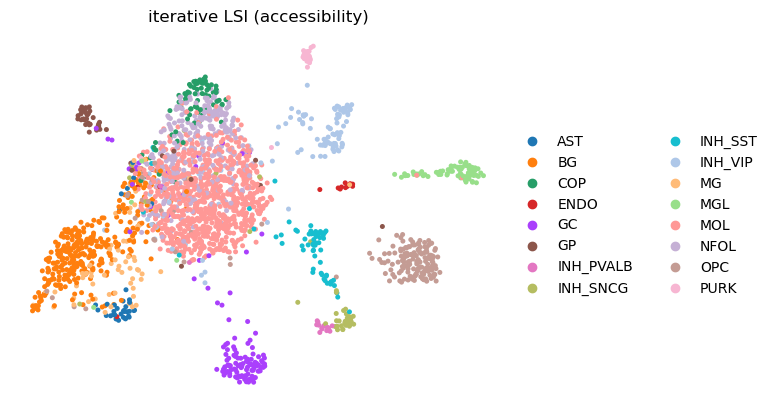

In [5]:
epi.tl.iterative_lsi(pm, n_components=30, iterations=2, var_features=50000, seed=0, verbose=False)
epi.tl.add_impute_weights(pm, use_rep="X_iterative_lsi", verbose=False)
pm.obs["Seurat_cell_type"] = rna.obs["Seurat_cell_type"].values
sc.pp.neighbors(pm, use_rep="X_iterative_lsi")
sc.tl.umap(pm)
sc.pl.umap(pm, color="Seurat_cell_type", frameon=False, title="iterative LSI (accessibility)")

## Search space

Gene coordinates come from the Ensembl 113 GTF (protein-coding transcripts; the columns of
the biomart query scenicplus uses). Every peak overlapping a gene body extended by 150 kb
on both sides is paired with the gene; `Distance` is the signed distance from the peak
midpoint to the gene body (0 inside the gene, negative upstream).

In [6]:
annot = scenic.gene_annotation_from_gtf(paths["Homo_sapiens.GRCh38.113.gtf.gz"])
t0 = time.time()
search_space = scenic.get_search_space(pm.var_names, rna.var_names, annot,
                                       upstream=(1000, 150000), downstream=(1000, 150000))
print(f"{len(search_space):,} region-gene pairs for {search_space.Gene.nunique():,} genes "
      f"in {time.time() - t0:.1f} s")
search_space.head()

466,263 region-gene pairs for 18,525 genes in 5.9 s


,Name,Gene,Distance
0,chr1:12591015-12591824,AADACL3,[124690]
1,chr1:12595032-12595653,AADACL3,[120768]
2,chr1:12595766-12596416,AADACL3,[120019]
3,chr1:12608987-12609866,AADACL3,[106684]
4,chr1:12614735-12615670,AADACL3,[100908]


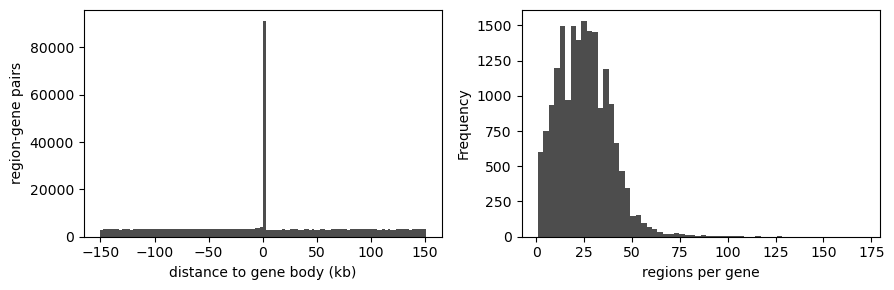

In [7]:
d = search_space.Distance.str.strip("[]").astype(int)
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].hist(d / 1e3, bins=120, color="0.3")
ax[0].set_xlabel("distance to gene body (kb)")
ax[0].set_ylabel("region-gene pairs")
search_space.Gene.value_counts().plot.hist(bins=60, ax=ax[1], color="0.3")
ax[1].set_xlabel("regions per gene")
plt.tight_layout()

## Genes to model

The full SCENIC+ run regresses every gene; here we use the 1,500 most variable genes (plus
the TFs among them) to keep the tutorial short. The functions take `targets=` for that.

In [8]:
norm = rna.copy()
sc.pp.normalize_total(norm, target_sum=1e4)
sc.pp.log1p(norm)
sc.pp.highly_variable_genes(norm, n_top_genes=1500, flavor="seurat")
motif2tf = pd.read_table(paths["motifs-v10nr_clust-nr.hgnc-m0.001-o0.0.tbl"], low_memory=False)
tf_names = sorted(set(motif2tf["gene_name"].dropna()) & set(rna.var_names))
targets = [g for g in rna.var_names[norm.var.highly_variable] if g in set(search_space.Gene)]
print(len(tf_names), "TFs with a motif annotation;", len(targets), "target genes")

1597 TFs with a motif annotation; 1026 target genes


## Region-to-gene links

For each gene, a gradient-boosting model (500 trees, `max_features=0.1`, seed 666 —
scenicplus defaults) predicts expression from the smoothed accessibility of its search-space
regions. `importance` is the feature importance (sums to 1 per gene) and `rho` the Spearman
correlation, used later to split activating and repressing links.

In [9]:
acc_regions = search_space.loc[search_space.Gene.isin(targets), "Name"].unique()
acc = epi.tl.impute_matrix(pm, list(acc_regions)).astype(np.float32)
t0 = time.time()
r2g = scenic.region_to_gene(rna, acc, search_space, importance="GBM", correlation="SR",
                            targets=targets, n_jobs=N_JOBS, accessibility_var_names=acc_regions)
print(f"{len(r2g):,} region-gene links for {r2g.target.nunique():,} genes in {time.time() - t0:.0f} s")
r2g.sort_values("importance_x_abs_rho", ascending=False).head(10)

26,436 region-gene links for 1,026 genes in 285 s


,target,region,importance,rho,importance_x_rho,importance_x_abs_rho,Distance
21819,SLC22A10,chr11:63445198-63445943,1.000000,0.329887,0.329887,0.329887,[-133787]
14482,LUZP2,chr11:24497907-24498598,0.317328,0.497620,0.157909,0.157909,[0]
26359,ZNF804A,chr2:184837546-184838418,0.249622,0.581379,0.145125,0.145125,[0]
4214,CDH6,chr5:31213394-31214217,0.617193,0.222688,0.137441,0.137441,[0]
13952,LILRB4,chr19:54523082-54523965,1.000000,0.123420,0.123420,0.123420,[120365]
24110,TENM1,chrX:124388279-124389087,0.321233,0.377291,0.121198,0.121198,[0]
9071,GAD2,chr10:26221316-26222208,0.280754,0.416989,0.117071,0.117071,[0]
11262,HTR2C,chrX:114584224-114585074,1.000000,0.115264,0.115264,0.115264,[0]
18843,PRR16,chr5:120405244-120406036,0.262787,0.437139,0.114874,0.114874,[58660]
6560,DACH2,chrX:86047078-86048002,0.616485,0.180749,0.111429,0.111429,[100911]


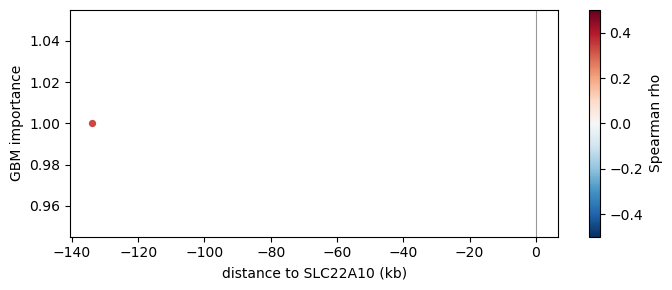

In [10]:
gene = r2g.groupby("target").importance_x_abs_rho.max().idxmax()
g = r2g[r2g.target == gene].copy()
g["kb"] = g.Distance.str.strip("[]").astype(int) / 1e3
fig, ax = plt.subplots(figsize=(7, 3))
sca = ax.scatter(g.kb, g.importance, c=g.rho, cmap="RdBu_r", vmin=-0.5, vmax=0.5, s=18)
ax.axvline(0, color="0.6", lw=0.8)
ax.set_xlabel(f"distance to {gene} (kb)")
ax.set_ylabel("GBM importance")
plt.colorbar(sca, label="Spearman rho")
plt.tight_layout()

Random forests (1000 trees, `max_features="sqrt"`) are the other importance model SCENIC+
offers; here on 60 genes.

In [11]:
t0 = time.time()
r2g_rf = scenic.region_to_gene(rna, acc, search_space, importance="RF", targets=targets[:60],
                               n_jobs=N_JOBS, accessibility_var_names=acc_regions)
both = r2g_rf.merge(r2g, on=["target", "region"], suffixes=("_rf", "_gbm"))
print(f"RF: {r2g_rf.target.nunique()} genes in {time.time() - t0:.0f} s; "
      f"Spearman(RF, GBM importance) = {both.importance_rf.corr(both.importance_gbm, method='spearman'):.2f}")

RF: 60 genes in 70 s; Spearman(RF, GBM importance) = 0.87


## TF-to-gene links (GRNBoost2)

Each target is regressed on the expression of all TFs with stochastic gradient boosting
(up to 5000 trees, `subsample=0.9`, out-of-bag early stopping); importances are multiplied by
the number of trees, as arboreto does. Genes without expression are skipped exactly (their
importances are zero), which upstream spends 5000 trees on.

In [12]:
t0 = time.time()
tf2g = scenic.tf_to_gene(rna, tf_names, targets=targets, n_jobs=N_JOBS)
print(f"{len(tf2g):,} TF-gene links in {time.time() - t0:.0f} s")
tf2g.head()

91,298 TF-gene links in 70 s


,TF,target,importance,regulation,rho
0,ABL1,TIMP3,0.923345,1,0.118451
1,ABL1,GABRE,2.226098,1,0.315982
2,ABL1,CAVIN2,0.009725,0,0.022295
3,ABL1,COL1A1,0.460762,1,0.178334
4,ABL1,RIN3,0.153152,1,0.064702


In [13]:
top = (tf2g[(tf2g.TF != tf2g.target) & (tf2g.regulation == 1)]
       .sort_values("importance", ascending=False).groupby("target").head(3))
markers = [m for m in ["GABRA6", "PAX6", "CBLN3", "MBP", "PLP1", "GFAP", "AQP4", "CSF1R", "PDGFRA"]
           if m in set(top.target)]
top[top.target.isin(markers)].sort_values(["target", "importance"], ascending=[True, False])

,TF,target,importance,regulation,rho
24650,ID4,AQP4,2.315365,1,0.509050
12786,EMX2,AQP4,2.182750,1,0.492884
19481,GLI3,AQP4,2.022018,1,0.651277
24938,IKZF1,CSF1R,2.799979,1,0.357249
59814,TAL1,CSF1R,2.362645,1,0.518000
36626,NFATC2,CSF1R,1.840618,1,0.527698
17590,FOXO1,GFAP,2.125797,1,0.436392
12754,EMX2,GFAP,1.992741,1,0.390407
19859,GLIS3,GFAP,1.968823,1,0.497145
42645,OLIG1,PDGFRA,4.742555,1,0.534757


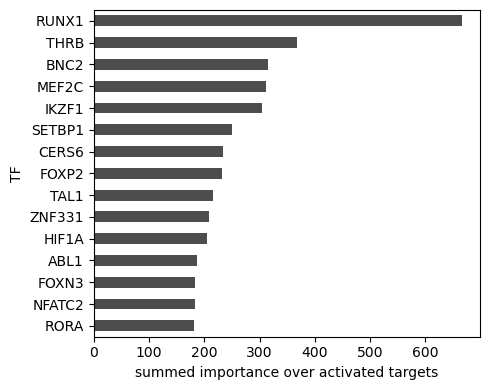

In [14]:
reg = (tf2g[(tf2g.TF != tf2g.target) & (tf2g.regulation == 1)]
       .groupby("TF").importance.sum().sort_values(ascending=False).head(15))
ax = reg[::-1].plot.barh(figsize=(5, 4), color="0.3")
ax.set_xlabel("summed importance over activated targets")
plt.tight_layout()

## Parity with scenicplus 1.0

Reference: scenicplus 1.0a2 / arboreto 0.1.6 / scikit-learn 1.3.2 on the same dataset
(2,313 multiome cells; topic-imputed accessibility; all 36,601 genes; seed 666), generated
outside this repository. Gates are pre-registered in
`tests/parity/scenic_links/MANIFEST.md`.

| Output | Rows | Result |
|---|---|---|
| Search space | 1,573,743 | byte-identical, same order (224 s → 17 s) |
| TF-to-gene `importance` (GRNBoost2) | 2,597,463 | identical links, **100 % bit-identical**, same row order |
| TF-to-gene `rho` / `regulation` | 2,597,463 | max abs err 5.5e-14 / 0 mismatches |
| Region-to-gene GBM `importance` | 1,573,743 | **100 % bit-identical**, same order |
| Region-to-gene RF `importance` | 1,573,743 | **100 % bit-identical**, same order |
| Region-to-gene `rho` (Spearman) | 1,573,743 | max abs err 4.4e-16, NaN positions identical |
| `n_jobs=1` vs `n_jobs=6` | — | identical |

Single-core speed against scikit-learn 1.3.2 + arboreto on the same inputs: GRNBoost2
1.06× per expressed gene (unexpressed genes are skipped exactly, ~40 % of the reference CPU
time), region-to-gene GBM 1.3×, RF 1.55×, search space 13×.